# Paso 3 · Respuesta en frecuencia (con Python)

Notebook del **Paso 3**: pasamos de calcular $P(j\omega)$ en **un** punto a estudiarla en **todas** las frecuencias y a leerla en un diagrama de Bode.

| Concepto matemático | Concepto de programación |
|---|---|
| fase ↔ retardo en segundos | funciones con unidades, conversión |
| $\omega$ (rad/s) y $f$ (Hz) | constantes y funciones de conversión |
| $P(j\omega)$ como función de $\omega$ | vectorización sobre arrays, `np.logspace` |
| ejes lineales frente a logarítmicos | `plt.semilogx`, comparar visualizaciones |
| curva a partir de los polos | asíntotas con `np.maximum` |
| el codo: $-3$ dB y $-45^\circ$ | búsqueda numérica con `np.argmin` |
| polos complejos: el pico | barrido de un parámetro ($\zeta$) con un bucle |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

## 1. Conocimiento previo: de grados de fase a segundos de retardo

Una senoidal $\sin(\omega t)$ **retrasada** $\tau$ segundos es $\sin(\omega(t-\tau))=\sin(\omega t-\omega\tau)$. Es decir, un desfase de $-\varphi$ grados equivale a un retardo

$$\tau=\frac{\varphi}{360\,f}=\frac{\varphi\cdot\pi/180}{\omega}.$$

Una función que lo calcula, **con las unidades en el nombre y en la documentación**:

In [2]:
def retardo_s(fase_grados, w):
    """Retardo en segundos equivalente a un desfase (grados) a la frecuencia w (rad/s)."""
    return np.radians(abs(fase_grados)) / w

print(f"-54.46° a 5 rad/s     -> {retardo_s(-54.46, 5)*1000:.1f} ms")
print(f"-90° a 1 rad/s        -> {retardo_s(-90, 1):.3f} s")
print(f"-90° a 100 rad/s      -> {retardo_s(-90, 100)*1000:.1f} ms  (misma fase, otro retardo)")

-54.46° a 5 rad/s     -> 190.1 ms
-90° a 1 rad/s        -> 1.571 s
-90° a 100 rad/s      -> 15.7 ms  (misma fase, otro retardo)


## 2. La frecuencia: $\omega$ en rad/s y $f$ en Hz

$\omega=2\pi f$. Los aparatos hablan en Hz; las fórmulas de control, en rad/s. **Mezclarlos es el error más común.**

In [3]:
hz_a_rads = lambda f: 2 * np.pi * np.asarray(f)
rads_a_hz = lambda w: np.asarray(w) / (2 * np.pi)

for f in [0.1, 1, 50, 1000]:
    print(f"{f:>7} Hz  =  {hz_a_rads(f):>10.3f} rad/s")
print("ω = 5 rad/s  =", rads_a_hz(5).round(3), "Hz")

    0.1 Hz  =       0.628 rad/s
      1 Hz  =       6.283 rad/s
     50 Hz  =     314.159 rad/s
   1000 Hz  =    6283.185 rad/s
ω = 5 rad/s  = 0.796 Hz


## 3. Respuesta en frecuencia: $P(j\omega)$ como función de $\omega$

Reutilizamos la planta del Paso 1, $P(s)=\dfrac{1}{(s+5)(s+30)}$, escrita con NumPy para que **acepte arrays**. Dos funciones auxiliares dan decibelios y fase en grados (**con `np.unwrap`** para que la fase no salte de $+180^\circ$ a $-180^\circ$):

In [4]:
def P(w):
    s = 1j * np.asarray(w, dtype=float)
    return 1 / ((s + 5) * (s + 30))

db = lambda z: 20 * np.log10(np.abs(z))
fase_deg = lambda z: np.squeeze(np.degrees(np.unwrap(np.atleast_1d(np.angle(z)))))

w = np.logspace(-2, 4, 7)              # 7 frecuencias de 0.01 a 10000, equiespaciadas en log
print(w)
print(db(P(w)).round(2))

[    0.01     0.1      1.      10.     100.    1000.   10000.  ]
[ -43.52  -43.52  -43.7   -50.97  -80.39 -120.   -160.  ]


`np.logspace(a, b, n)` genera $n$ puntos entre $10^a$ y $10^b$ **equiespaciados en logaritmo** (cada uno es un factor constante mayor que el anterior). `np.linspace` los separa en lineal. Para respuesta en frecuencia casi siempre queremos `logspace`.

### Un barrido en siete frecuencias

In [5]:
w7 = np.array([0.1, 1, 5, 10, 30, 100, 1000])
z7 = P(w7)
print(f"{'ω (rad/s)':>10} {'|P|':>12} {'dB':>9} {'fase':>10}")
for wi, zi in zip(w7, z7):
    print(f"{wi:>10g} {abs(zi):>12.3e} {db(zi):>9.2f} {fase_deg(zi):>9.2f}°")

 ω (rad/s)          |P|        dB       fase
       0.1    6.665e-03    -43.52     -1.34°
         1    6.534e-03    -43.70    -13.22°
         5    4.650e-03    -46.65    -54.46°
        10    2.828e-03    -50.97    -81.87°
        30    7.750e-04    -62.21   -125.54°
       100    9.566e-05    -80.39   -160.44°
      1000    9.995e-07   -120.00   -178.00°


Qué se observa: la magnitud cae **más de tres órdenes de magnitud** (de $6.7\cdot10^{-3}$ a $10^{-6}$) y la fase va de $0^\circ$ hacia $-180^\circ$. Las filas $\omega=5$ y $\omega=10$ ya las conocías del Paso 1.

## 4. Primer intento: dibujarlo con ejes lineales

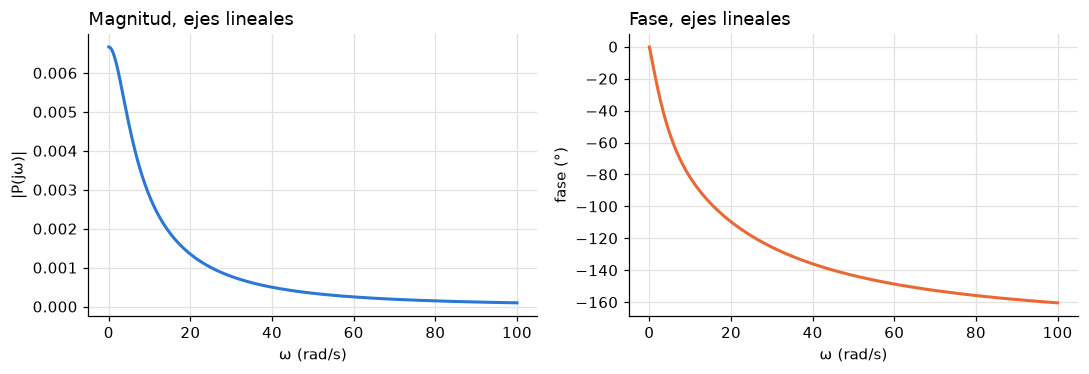

In [6]:
wl = np.linspace(0.01, 100, 4000)
zl = P(wl)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(wl, np.abs(zl), color=AZUL, lw=2); ax[0].set_title("Magnitud, ejes lineales", loc="left")
ax[0].set_xlabel("ω (rad/s)"); ax[0].set_ylabel("|P(jω)|")
ax[1].plot(wl, fase_deg(zl), color=NARANJA, lw=2); ax[1].set_title("Fase, ejes lineales", loc="left")
ax[1].set_xlabel("ω (rad/s)"); ax[1].set_ylabel("fase (°)")
plt.tight_layout(); plt.show()

**Problema.** Casi toda la información está pegada al eje vertical (entre 0 y 30 rad/s) y el resto de la gráfica es una cola casi plana. Hacen falta **otras escalas**.

## 5. La solución: escala logarítmica en $\omega$ y decibelios (Bode)

Eje horizontal logarítmico (`semilogx`) y magnitud en dB. Es el **diagrama de Bode**:

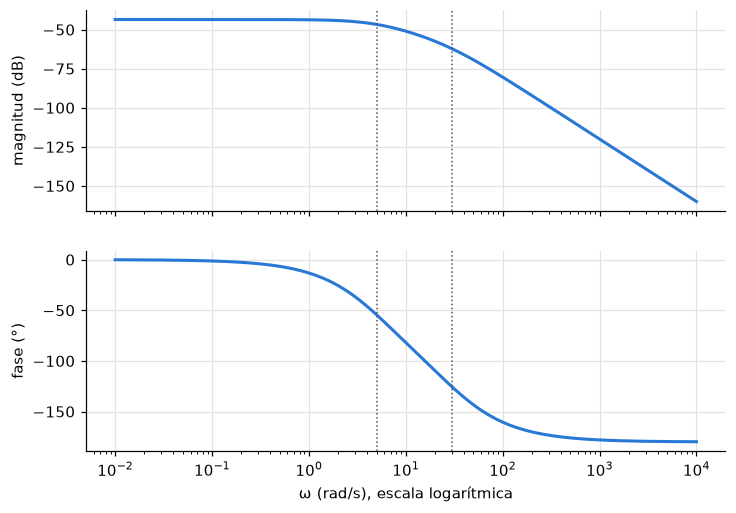

In [7]:
def bode(sistemas, wmin=1e-2, wmax=1e4, n=1500, ax=None):
    """sistemas: dict nombre -> función de w. Dibuja magnitud (dB) y fase (°)."""
    w = np.logspace(np.log10(wmin), np.log10(wmax), n)
    if ax is None:
        fig, ax = plt.subplots(2, 1, figsize=(7.5, 5.2), sharex=True)
    colores = [AZUL, NARANJA, "#2a9d8f", GRIS]
    for (nombre, f), col in zip(sistemas.items(), colores):
        z = f(w)
        ax[0].semilogx(w, db(z), color=col, lw=2, label=nombre)
        ax[1].semilogx(w, fase_deg(z), color=col, lw=2)
    ax[0].set_ylabel("magnitud (dB)"); ax[1].set_ylabel("fase (°)")
    ax[1].set_xlabel("ω (rad/s), escala logarítmica")
    if len(sistemas) > 1: ax[0].legend(fontsize=8)
    return w, ax

w, ax = bode({"P": P})
for a in ax:
    for wc in (5, 30): a.axvline(wc, color=GRIS, ls=":", lw=1)
plt.show()

Ahora sí se ve la estructura: una meseta, dos **codos** (en los polos, $\omega=5$ y $\omega=30$) y caídas de pendiente cada vez más fuerte.

## 6. Cómo leer la curva a partir de los polos

Para cada **polo real** en $s=-p$:

- por debajo de $\omega=p$ el factor aporta ≈ $0$ dB;
- por encima, **cae $20$ dB por década** ($-6$ dB por octava);
- la fase pasa de $0^\circ$ a $-90^\circ$ alrededor de $\omega=p$.

La aproximación **asintótica** de la magnitud es la suma de la ganancia en continua y de un término por polo. Se programa en una línea con `np.maximum`: cada término es $0$ por debajo del codo y $-20\log_{10}(\omega/p)$ por encima.

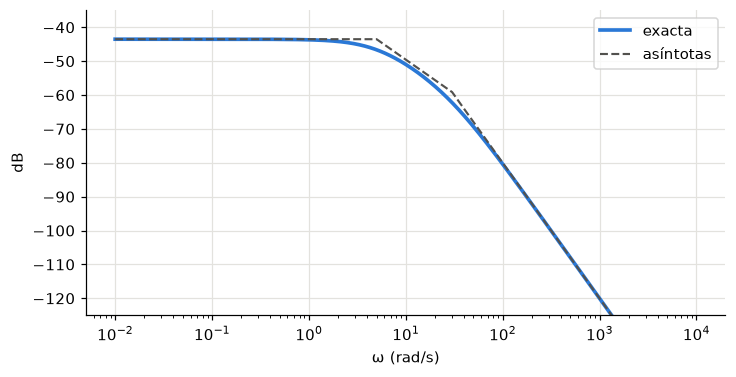

ganancia en continua P(0) = -43.52 dB (dibujo del Paso 3: −43.52 dB)


In [8]:
def asintota_db(w, polos, ceros=(), dc_db=0.0):
    """Aproximación de Bode de la magnitud: dc_db + sum de términos por polo/cero (reales)."""
    w = np.asarray(w, dtype=float)
    a = dc_db * np.ones_like(w)
    for p in polos: a -= np.maximum(0, 20 * np.log10(w / p))
    for c in ceros: a += np.maximum(0, 20 * np.log10(w / c))
    return a

w = np.logspace(-2, 4, 1500)
dc = db(P(0))                            # ganancia en continua = 1/(5*30)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.semilogx(w, db(P(w)), color=AZUL, lw=2.4, label="exacta")
ax.semilogx(w, asintota_db(w, polos=[5, 30], dc_db=dc), color=GRIS, ls="--", lw=1.4, label="asíntotas")
ax.set_xlabel("ω (rad/s)"); ax.set_ylabel("dB"); ax.set_ylim(-125, -35); ax.legend()
plt.show()
print(f"ganancia en continua P(0) = {dc:.2f} dB (dibujo del Paso 3: −43.52 dB)")

## 7. El codo: qué pasa justo en $\omega=$ polo

En el polo, el factor vale $|j p+p|=\sqrt2\,p$, es decir **$-3$ dB** respecto a su asíntota, y su fase es $-45^\circ$. Lo comprobamos para el polo en $p=5$ (aislado) y buscamos numéricamente el codo en la curva completa:

In [9]:
Pp = lambda w, p=5: p / (1j * np.asarray(w) + p)      # un solo polo, ganancia 1 en continua
print(f"un solo polo, en w=p: {db(Pp(5)):.3f} dB (esperado -3.010), fase {fase_deg(Pp(5)):.2f}° (esperado -45)")

# Búsqueda numérica: ¿en qué w la magnitud ha caído 3 dB respecto a la asíntota baja?
w = np.logspace(-1, 3, 20000)
caida = db(Pp(w)) - 0                         # asíntota baja = 0 dB
i = np.argmin(np.abs(caida + 3.0103))         # índice donde la caída es más cercana a -3 dB
print(f"caída de 3 dB encontrada en ω = {w[i]:.3f} rad/s (polo en 5)")

un solo polo, en w=p: -3.010 dB (esperado -3.010), fase -45.00° (esperado -45)
caída de 3 dB encontrada en ω = 4.999 rad/s (polo en 5)


**Programación.** `np.argmin(|f(w) − objetivo|)` es un patrón muy útil: *buscar* el valor de $\omega$ donde una curva cruza un nivel. Lo usaremos más adelante para márgenes de fase y ancho de banda.

## 8. Un cero cambia la curva

Un cero real en $s=-z$ hace lo contrario que un polo: la magnitud **sube** $20$ dB por década a partir de $\omega=z$ y la fase **gana** hasta $+90^\circ$.

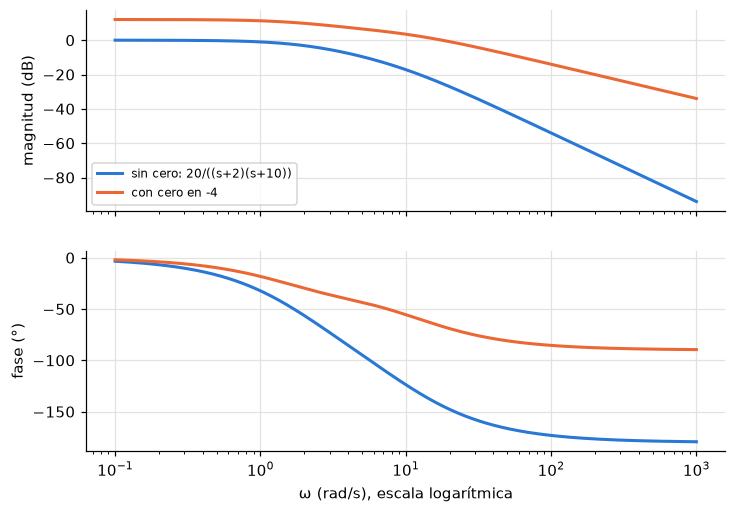

In [10]:
Pcero = lambda w: 20 * (1j*np.asarray(w) + 4) / ((1j*np.asarray(w) + 2) * (1j*np.asarray(w) + 10))
Pnormal = lambda w: 20 / ((1j*np.asarray(w) + 2) * (1j*np.asarray(w) + 10))
w, ax = bode({"sin cero: 20/((s+2)(s+10))": Pnormal, "con cero en -4": Pcero}, wmin=1e-1, wmax=1e3)
plt.show()

## 9. Polos complejos: el pico

Con dos polos complejos conjugados, escritos como $\dfrac{\omega_n^2}{s^2+2\zeta\omega_n s+\omega_n^2}$, la magnitud presenta un **pico de resonancia** cerca de $\omega_n$ cuando el amortiguamiento $\zeta$ es pequeño. Hacemos un **barrido del parámetro** $\zeta$ con un bucle:

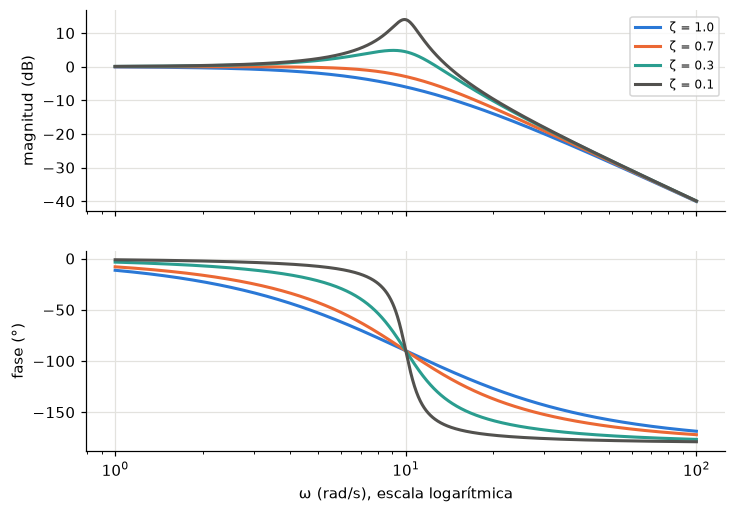

    ζ  pico (dB)   teórico
  1.0      -0.09      0.00
  0.7       0.00      0.00
  0.3       4.85      4.85
  0.1      14.02     14.02


In [11]:
wn = 10.0
seg = lambda zeta: (lambda w: wn**2 / ((1j*np.asarray(w))**2 + 2*zeta*wn*(1j*np.asarray(w)) + wn**2))

zetas = [1.0, 0.7, 0.3, 0.1]
w, ax = bode({f"ζ = {z}": seg(z) for z in zetas}, wmin=1, wmax=100)
plt.show()

print(f"{'ζ':>5} {'pico (dB)':>10} {'teórico':>9}")
for z in zetas:
    f = seg(z)(w)
    pico = db(f).max()
    teo = -20*np.log10(2*z*np.sqrt(1 - z**2)) if z < 0.7071 else 0.0
    print(f"{z:>5} {pico:>10.2f} {teo:>9.2f}")

Para $\zeta<1/\sqrt2\approx0.707$ aparece pico y su altura es $-20\log_{10}\!\big(2\zeta\sqrt{1-\zeta^2}\big)$ dB: la tabla de arriba lo verifica. **Menos amortiguamiento ⇒ pico más alto**, y la fase cae de $0^\circ$ a $-180^\circ$ **más bruscamente**.

## 10. Ejercicio del Paso 3

Sea $P(s)=\dfrac{20}{(s+2)(s+10)}$.

1. Polos y codos.
2. Ganancia en continua $P(0)$ en dB y fase.
3. $P(j2)$ factor a factor (magnitud en dB, fase).
4. Dibuja el Bode exacto y las asíntotas, y comprueba que en $\omega=2$ la curva está $\approx3$ dB por debajo de la asíntota.

**Tu turno.**

In [12]:
Pej = lambda w: 20 / ((1j*np.asarray(w) + 2) * (1j*np.asarray(w) + 10))
# 1-2) polos, codos y P(0)
# 3) P(j2) factor a factor
# 4) Bode + asintota_db(w, polos=[2, 10], dc_db=...)
# escribe aquí tu código

Polos en s = -2 y s = -10  ->  codos en w = 2 y w = 10 rad/s
P(0) = 1.000+0.000j = 0.00 dB, fase 0.0°
P(j2): factores s+2 = 2.828∠45.00°, s+10 = 10.198∠11.31°
      magnitud 0.6934 = -3.18 dB, fase -56.31°  (diapositivas: -3.18 dB, -56.31°)


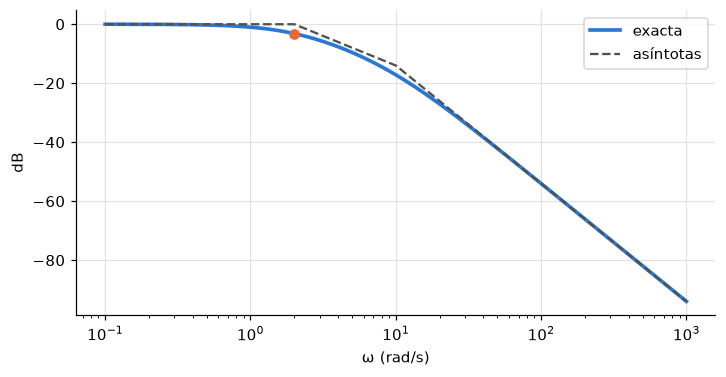

distancia a la asíntota en w=2: -3.18 dB (≈ -3 dB, el codo)


In [13]:
print("Polos en s = -2 y s = -10  ->  codos en w = 2 y w = 10 rad/s")
print(f"P(0) = {Pej(0):.3f} = {db(Pej(0)):.2f} dB, fase {fase_deg(Pej(0)):.1f}°")

s = 2j
m = 20 / (abs(s + 2) * abs(s + 10))
f = -np.degrees(np.angle(s + 2) + np.angle(s + 10))
print(f"P(j2): factores s+2 = {abs(s+2):.3f}∠{np.degrees(np.angle(s+2)):.2f}°, s+10 = {abs(s+10):.3f}∠{np.degrees(np.angle(s+10)):.2f}°")
print(f"      magnitud {m:.4f} = {20*np.log10(m):.2f} dB, fase {f:.2f}°  (diapositivas: -3.18 dB, -56.31°)")
assert np.isclose(Pej(2), m*np.exp(1j*np.radians(f)))

w = np.logspace(-1, 3, 1500)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.semilogx(w, db(Pej(w)), color=AZUL, lw=2.4, label="exacta")
ax.semilogx(w, asintota_db(w, [2, 10], dc_db=db(Pej(0))), color=GRIS, ls="--", label="asíntotas")
ax.plot(2, db(Pej(2)), "o", color=NARANJA); ax.set_xlabel("ω (rad/s)"); ax.set_ylabel("dB"); ax.legend()
plt.show()
print("distancia a la asíntota en w=2:", round(db(Pej(2)) - asintota_db(2, [2, 10], dc_db=db(Pej(0))), 2), "dB (≈ -3 dB, el codo)")

## 11. Resumen

- $P(j\omega)$ para **todas** las $\omega$ se calcula con **una** llamada si la función está escrita con operaciones de NumPy (vectorización).
- Con ejes lineales casi no se ve nada; con $\omega$ logarítmica y dB aparece el diagrama de **Bode**.
- Cada polo real: codo en $\omega=p$, **−3 dB** y **−45°** justo en el codo, luego −20 dB/década. Cada cero hace lo contrario. Polos complejos poco amortiguados dan un **pico**.
- Patrones de programación útiles: `np.logspace`, `np.unwrap`, `np.argmin(|f−objetivo|)`, barrido de un parámetro con bucle, asíntotas con `np.maximum`.

**Siguiente:** Paso 4, decibelios y escala logarítmica con más detalle; y después realimentación, Nichols y el método QFT.